# Phase 1 — Exploratory Data Analysis (EDA)

**Project:** Explainable and Personalized Workplace Stress Prediction System  
**Dataset:** `data/processed/clean.csv` (68 Google Forms responses, 27 features + 1 target)  
**Note on sample size:** With only 68 rows, all patterns below are *exploratory observations* that suggest associations in this sample — they do not prove cause-and-effect or statistical significance.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Add project root to sys.path so we can import shared/features.py
# (Single source of truth for feature names and category orders)
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "shared").exists():
    PROJECT_ROOT = PROJECT_ROOT.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared.features import (
    FEATURE_MAP,
    ORDINAL_CATEGORIES,
    ORDINAL_FEATURES,
    TARGET,
)

CLEAN_CSV = PROJECT_ROOT / "data" / "processed" / "clean.csv"
FIG_DIR = PROJECT_ROOT / "artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# keep_default_na=False ensures the valid category "None" is not read as NaN
df = pd.read_csv(CLEAN_CSV, keep_default_na=False)
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns; missing values = {df.isnull().sum().sum()}")

Matplotlib is building the font cache; this may take a moment.


Loaded 68 rows x 28 columns; missing values = 0


In [2]:
# Global plot styling matching docs/design.md risk colors
sns.set_theme(style="whitegrid", context="notebook")
STRESS_ORDER = TARGET["categories"]  # ["Low", "Medium", "High"]
STRESS_COLORS = {
    "Low": "#16A34A",
    "Medium": "#D97706",
    "High": "#DC2626",
}
PALETTE = [STRESS_COLORS[c] for c in STRESS_ORDER]

def save_fig(fig, filename: str, caption: str) -> None:
    """Attach a one-line caption at the bottom and save to artifacts/figures/."""
    fig.text(0.5, 0.01, caption, ha="center", va="bottom", fontsize=9.5, style="italic", color="#374151")
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    out_path = FIG_DIR / filename
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved: {out_path.name} — {caption}")

## 1. Overall Stress Level Distribution
Question: *How are the 68 survey responses distributed across Low, Medium, and High stress?*

Saved: 01_stress_distribution.png — Caption: Medium (30, 44.1%) and High (27, 39.7%) dominate this 68-row sample, while Low stress is under-represented (11, 16.2%).


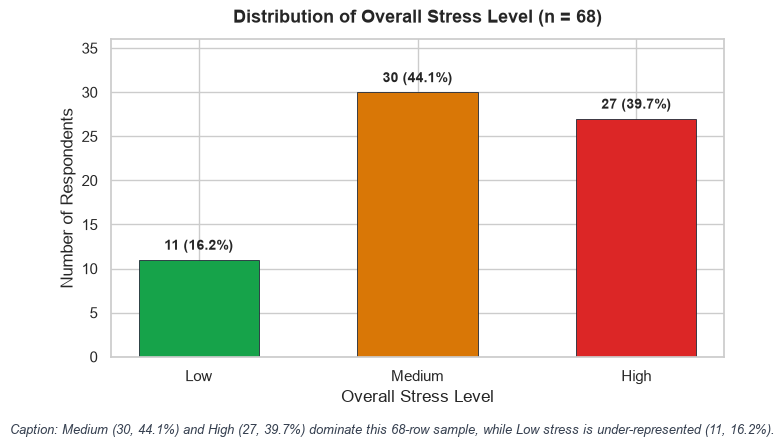

In [3]:
counts = df["stress_level"].value_counts().reindex(STRESS_ORDER, fill_value=0)
total = len(df)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(counts.index, counts.values, color=PALETTE, width=0.55, edgecolor="#1F2937", linewidth=0.6)
for bar, cnt in zip(bars, counts.values):
    pct = cnt / total * 100
    ax.text(bar.get_x() + bar.get_width() / 2, cnt + 0.8, f"{cnt} ({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("Distribution of Overall Stress Level (n = 68)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Overall Stress Level")
ax.set_ylabel("Number of Respondents")
ax.set_ylim(0, counts.max() + 6)

save_fig(
    fig,
    "01_stress_distribution.png",
    "Caption: Medium (30, 44.1%) and High (27, 39.7%) dominate this 68-row sample, while Low stress is under-represented (11, 16.2%)."
)
plt.show()

## 2. Stress vs Key Lifestyle & Work Factors
We plot grouped count bars (with exact counts labeled) for the four key factors: `sleep_duration`, `overtime_frequency`, `financial_pressure`, and `work_life_balance`.

In [4]:
def plot_stress_vs_factor(feature_name: str, filename: str, caption: str, rotate_x: int = 15) -> None:
    """Plot a grouped bar chart of stress_level counts across ordered categories of a feature."""
    meta = FEATURE_MAP[feature_name]
    cat_order = meta["categories"]
    label = meta["display_label"]

    # Cross-tabulate counts using the exact category order from shared/features.py
    ct = pd.crosstab(df[feature_name], df["stress_level"]).reindex(index=cat_order, columns=STRESS_ORDER, fill_value=0)
    print(f"\n--- {label} vs Stress Level (counts) ---")
    print(ct)

    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ct.plot(kind="bar", ax=ax, color=PALETTE, width=0.75, edgecolor="#1F2937", linewidth=0.5)

    # Label non-zero bars with exact respondent counts
    for container in ax.containers:
        labels = [str(int(v)) if v > 0 else "" for v in container.datavalues]
        ax.bar_label(container, labels=labels, padding=2, fontsize=8.5)

    ax.set_title(f"Stress Level Counts by {label} (n = 68)", fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of Respondents")
    ax.set_xticklabels(cat_order, rotation=rotate_x, ha="right" if rotate_x > 0 else "center")
    ax.set_ylim(0, ct.values.max() + 3)
    ax.legend(title="Stress Level", loc="upper right")

    save_fig(fig, filename, caption)
    plt.show()


--- Sleep duration vs Stress Level (counts) ---
stress_level       Low  Medium  High
sleep_duration                      
Less than 5 hours    1       4     7
5-6 hours            1       5     9
6-7 hours            1      10     7
7-8 hours            7       9     0
More than 8 hours    1       2     4


Saved: 02_stress_vs_sleep_duration.png — Caption: Shorter sleep (5-6 hours) shows mostly High/Medium stress counts, suggesting shorter sleep is linked with higher stress (n = 68).


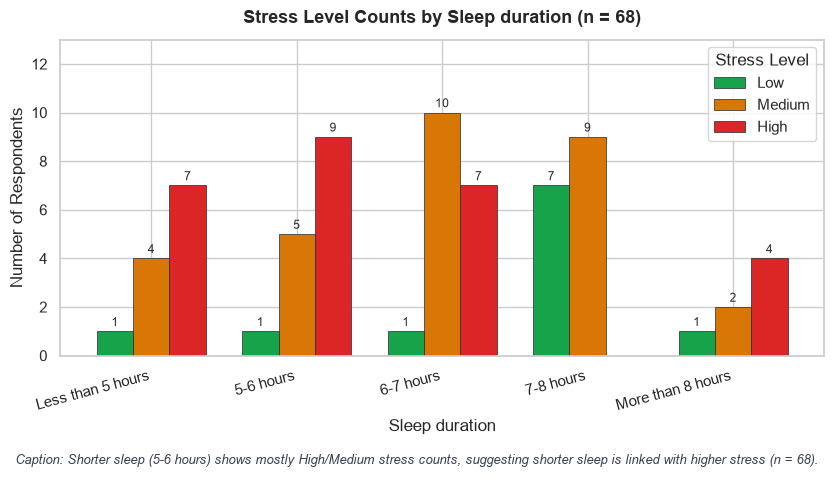


--- Overtime frequency vs Stress Level (counts) ---
stress_level        Low  Medium  High
overtime_frequency                   
Never                 5       5     4
Rarely                6       6     2
Sometimes             0      19     7
Often                 0       0     8
Very Often            0       0     6


Saved: 03_stress_vs_overtime_frequency.png — Caption: Respondents reporting 'Often' or 'Very Often' overtime are concentrated in Medium/High stress, suggesting overtime raises stress (n = 68).


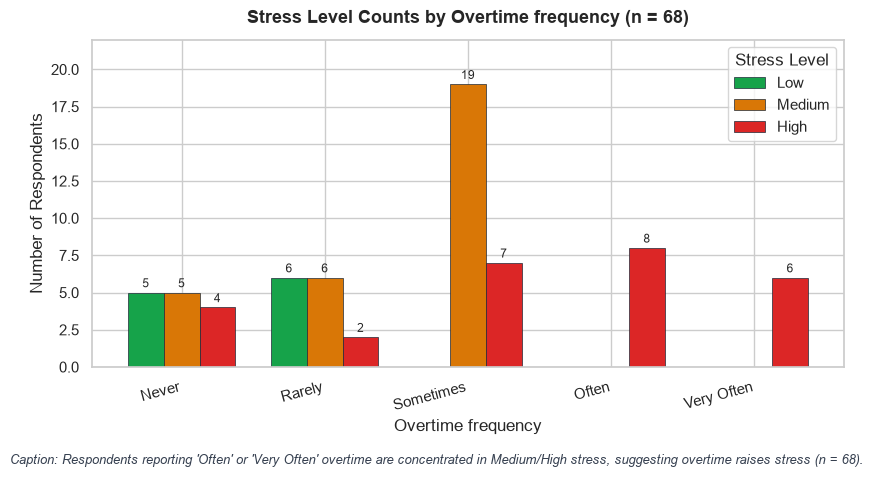


--- Financial pressure vs Stress Level (counts) ---
stress_level        Low  Medium  High
financial_pressure                   
Very Low              2       1     1
Low                   3       2     1
Moderate              3      16     7
High                  3       7     9
Very High             0       4     9


Saved: 04_stress_vs_financial_pressure.png — Caption: High and Very High financial pressure groups show more High-stress counts than Low-pressure groups in this 68-row sample.


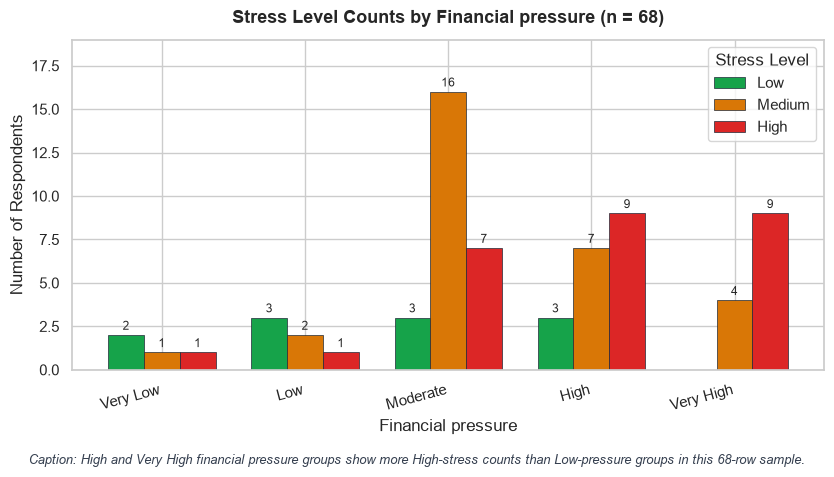


--- Work-life balance vs Stress Level (counts) ---
stress_level       Low  Medium  High
work_life_balance                   
Very Poor            1       1    10
Poor                 1       2    11
Average              1      19     5
Good                 6       8     0
Excellent            2       0     1


Saved: 05_stress_vs_work_life_balance.png — Caption: Poor/Very Poor work-life balance leans toward High stress, while Good/Excellent leans toward Low/Medium stress (n = 68).


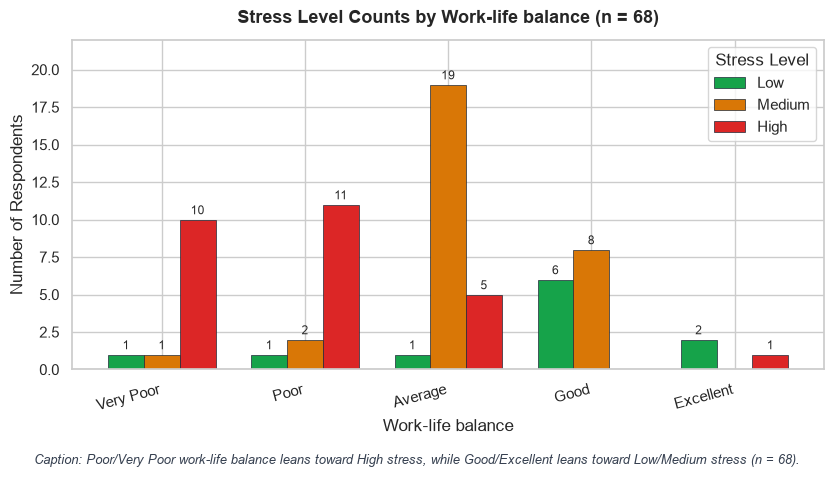

In [5]:
plot_stress_vs_factor(
    "sleep_duration",
    "02_stress_vs_sleep_duration.png",
    "Caption: Shorter sleep (5-6 hours) shows mostly High/Medium stress counts, suggesting shorter sleep is linked with higher stress (n = 68)."
)

plot_stress_vs_factor(
    "overtime_frequency",
    "03_stress_vs_overtime_frequency.png",
    "Caption: Respondents reporting 'Often' or 'Very Often' overtime are concentrated in Medium/High stress, suggesting overtime raises stress (n = 68)."
)

plot_stress_vs_factor(
    "financial_pressure",
    "04_stress_vs_financial_pressure.png",
    "Caption: High and Very High financial pressure groups show more High-stress counts than Low-pressure groups in this 68-row sample."
)

plot_stress_vs_factor(
    "work_life_balance",
    "05_stress_vs_work_life_balance.png",
    "Caption: Poor/Very Poor work-life balance leans toward High stress, while Good/Excellent leans toward Low/Medium stress (n = 68)."
)

## 3. Spearman Correlation (Ordinal Features vs Stress)
Why Spearman? All 25 ordinal features and `stress_level` (`Low=0, Medium=1, High=2`) are ranked categories rather than continuous numbers, so Spearman rank correlation measures monotonic association without assuming equal spacing between categories.

Top 10 ordinal features by |Spearman correlation| with stress_level:
  workload_level                  : +0.666
  work_life_balance               : -0.629
  job_satisfaction                : -0.605
  career_growth_pressure          : +0.601
  overtime_frequency              : +0.548
  after_hours_communication       : +0.543
  sleep_quality                   : -0.513
  family_responsibility_pressure  : +0.508
  thinks_about_work_outside       : +0.485
  exercise_frequency              : -0.474


Saved: 06_spearman_top10_heatmap.png — Caption: Top 10 ordinal features ranked by |Spearman r| with stress (Low=0, Medium=1, High=2); correlations suggest patterns in this 68-row sample.


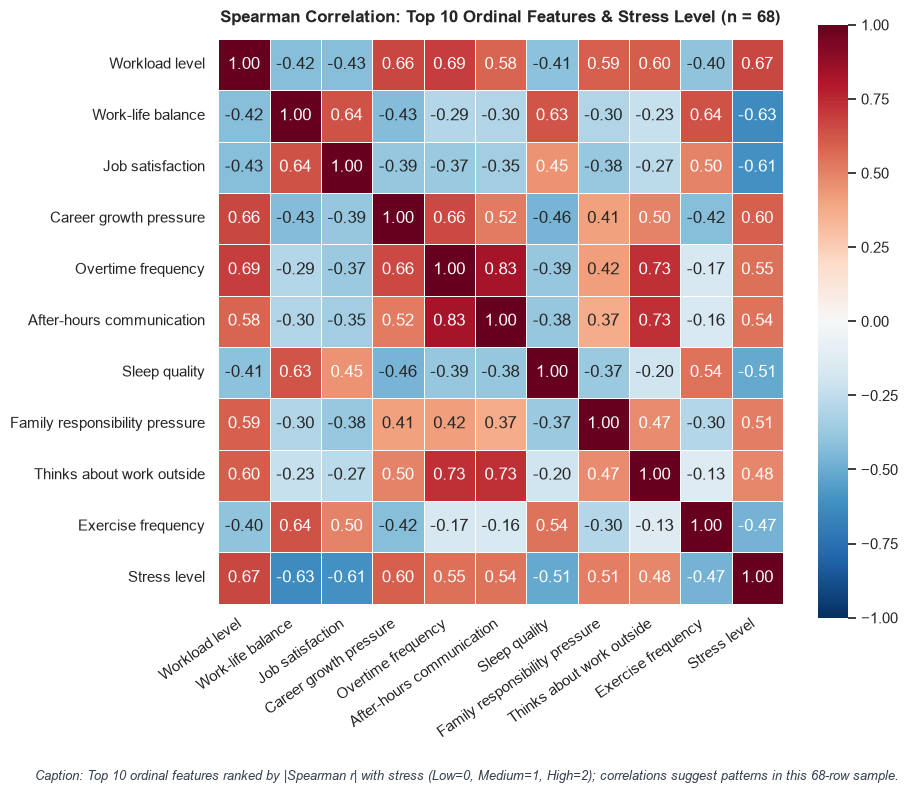

In [6]:
# Encode every ordinal feature using its exact LOW -> HIGH category index from shared/features.py
ord_df = pd.DataFrame(index=df.index)
for feat, cats in zip(ORDINAL_FEATURES, ORDINAL_CATEGORIES):
    cat_map = {val: idx for idx, val in enumerate(cats)}
    ord_df[feat] = df[feat].map(cat_map)

target_map = {val: idx for idx, val in enumerate(TARGET["categories"])}  # Low=0, Medium=1, High=2
ord_df["stress_level"] = df["stress_level"].map(target_map)

# Compute full Spearman correlation matrix
corr_matrix = ord_df.corr(method="spearman")
stress_corr = corr_matrix["stress_level"].drop("stress_level")

# Select top 10 features by absolute Spearman correlation with stress_level
top10_feats = stress_corr.abs().sort_values(ascending=False).head(10).index.tolist()
print("Top 10 ordinal features by |Spearman correlation| with stress_level:")
for f in top10_feats:
    print(f"  {f:32s}: {stress_corr[f]:+.3f}")

# Heatmap of top 10 features + stress_level
heatmap_cols = top10_feats + ["stress_level"]
sub_corr = corr_matrix.loc[heatmap_cols, heatmap_cols]
pretty_names = [FEATURE_MAP[c]["display_label"] if c in FEATURE_MAP else "Stress level" for c in heatmap_cols]
sub_corr.index = pretty_names
sub_corr.columns = pretty_names

fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(
    sub_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Spearman Correlation: Top 10 Ordinal Features & Stress Level (n = 68)", fontsize=12.5, fontweight="bold", pad=12)
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

save_fig(
    fig,
    "06_spearman_top10_heatmap.png",
    "Caption: Top 10 ordinal features ranked by |Spearman r| with stress (Low=0, Medium=1, High=2); correlations suggest patterns in this 68-row sample."
)
plt.show()

## 4. Stress Distribution by Job Level
Question: *How do stress level counts differ across Junior, Mid-Manager, and Senior roles?*


--- Job level vs Stress Level (counts) ---
stress_level       Low  Medium  High
job_level                           
Junior Level         6      18    13
Mid-Manager Level    2       8     6
Senior Level         3       4     8


Saved: 07_stress_by_job_level.png — Caption: Junior roles make up 37 of 68 responses with mostly Medium/High stress; Mid-Manager (16) and Senior (15) groups are small.


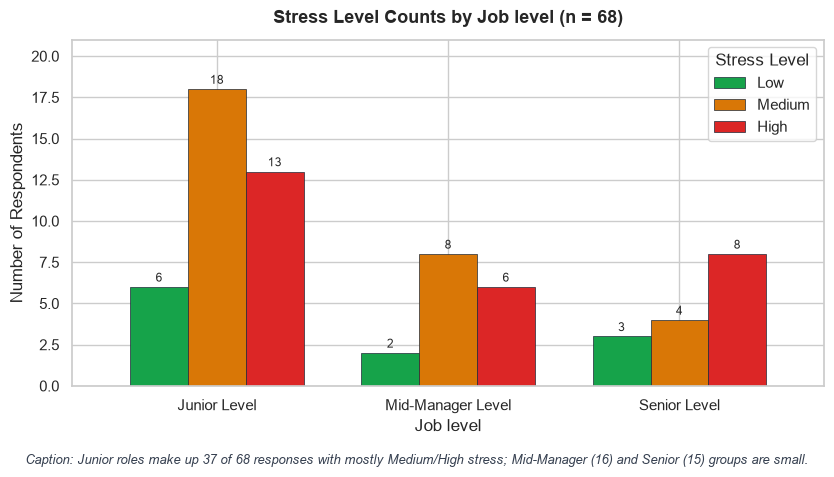

In [7]:
plot_stress_vs_factor(
    "job_level",
    "07_stress_by_job_level.png",
    "Caption: Junior roles make up 37 of 68 responses with mostly Medium/High stress; Mid-Manager (16) and Senior (15) groups are small.",
    rotate_x=0,
)

## 5. Sample Demographics Overview
Question: *Who is represented in this 68-person survey sample?*

Saved: 08_demographics_overview.png — Caption: Sample is predominantly young (22-28: 46/68), male (50/68), and single (48/68), which limits generalization to all workers.


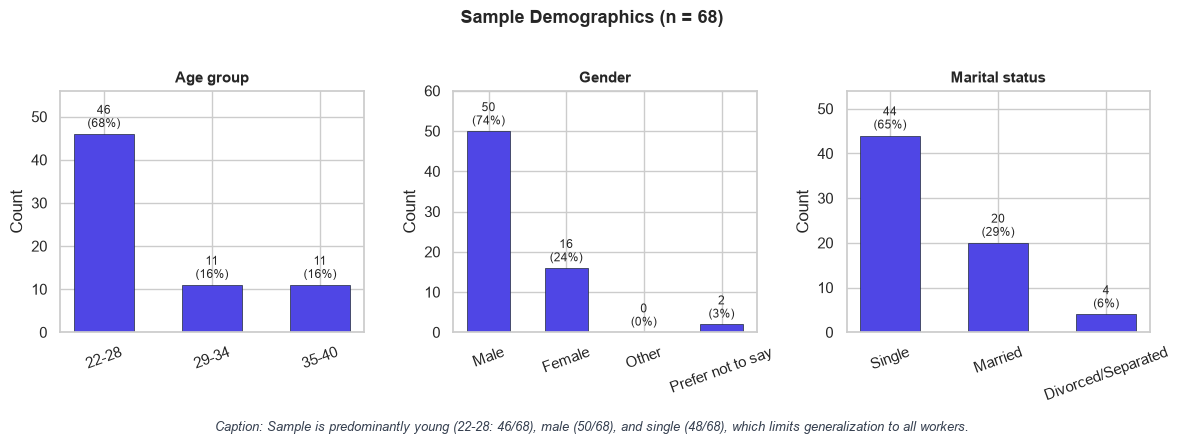

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
demo_cols = ["age_group", "gender", "marital_status"]

for ax, col in zip(axes, demo_cols):
    cats = FEATURE_MAP[col]["categories"]
    vc = df[col].value_counts().reindex(cats, fill_value=0)
    bars = ax.bar(vc.index, vc.values, color="#4F46E5", width=0.55, edgecolor="#1F2937", linewidth=0.5)
    for bar, cnt in zip(bars, vc.values):
        pct = cnt / len(df) * 100
        ax.text(bar.get_x() + bar.get_width() / 2, cnt + 0.8, f"{cnt}\n({pct:.0f}%)",
                ha="center", va="bottom", fontsize=8.5)
    ax.set_title(FEATURE_MAP[col]["display_label"], fontsize=11, fontweight="bold")
    ax.set_ylabel("Count")
    ax.set_ylim(0, vc.max() + 10)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Sample Demographics (n = 68)", fontsize=13, fontweight="bold", y=1.02)
save_fig(
    fig,
    "08_demographics_overview.png",
    "Caption: Sample is predominantly young (22-28: 46/68), male (50/68), and single (48/68), which limits generalization to all workers."
)
plt.show()